# Loan Default Risk Analysis

# Questions to Answer:

-What is the overall default rate, and how does it break down by credit score range (e.g., 520–599, 600–649, 650–699, 700–749, 750+)? Which credit score bucket has the highest default rate?

-Is there a relationship between a borrower’s debt-to-income (DTI) ratio and the likelihood of defaulting? What DTI threshold would you recommend as a cutoff for loan approval?

-Which loan purposes have the highest default rates, and does the average loan amount differ significantly between defaulted and non-defaulted loans?

-How do employment status and years employed affect default risk? Are borrowers with less than 2 years of employment significantly more likely to default?

# Key Findings:

The overall default rate is 24%. However, it varies widely from one credit score group to another. It starts with a 49% default rate at the lowest credit group and gets down to an 11% default rate in the group with the highest credit score.

Top 3 factors for defaulting:

1. Credit score. I would recommend picking borrowers with higher credit scores, specifically from 700, and avoiding people with a credit score lower than 600. Everyone in the middle should be additionally checked to determine if a loan should be given.
2. DTI ratio. I would recommend monitoring borrowers more closely the higher their DTI gets. Borrowers with a DTI lower than 40 default at about 13%, and above 40 at about 32% default rate. There is no sharp breakpoint: for any cutoff between 40 and 60, borrowers above it default 16 to 20 percentage points more often. A cutoff at 50 would flag 270 applicants, which is 45% of all. Therefore, I would recommend using a DTI of more than 50 as a trigger for a manual review, rather than an automatic rejection.
3. Interest rate. Even though it has a similar correlation to DTI, it is not as important, because higher rates are associated with more defaults, but likely reflect risk rather than cause it.

Days delinquent. Even though it has the highest correlation across all the other factors, it was not taken into account as it is rather an outcome and not a cause.

Wedding, auto and home improvement loans have slightly higher risks, but the evidence is not conclusive, as the sample size is too small. The average loan amount for those who defaulted and not, is almost identical. Therefore, it should not be taken into account during the loaning process.

Employment status does not bring significant default risks. However, borrowers who are employed for less than 2 years show noticeably higher chances of default. Their chance of default is 35% compared to only 23% for those who work for 2 or more years.

Dataset contains 601 loans and 500 borrowers, which means that some of them got 2 loans instead of 1.
Vertical Lines on Point Plots are 95% confidence intervals. Therefore, overlap means that the difference may not be real.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
loan_applications = pd.read_csv("data/loan_applications.csv")
loan_applications

,loan_id,borrower_id,application_date,loan_purpose,loan_amount,term_months,interest_rate,monthly_payment,dti_ratio,loan_status,days_delinquent,defaulted
0,LN-00001,BRW-0001,2024-01-08,Vacation,16100.0,36,13.05,542.86,55.5,Paid Off,0,0
1,LN-00002,BRW-0001,2024-08-13,Major Purchase,5600.0,48,14.21,153.62,40.4,Default,138,1
2,LN-00003,BRW-0002,2025-06-28,Moving,44700.0,36,12.37,1492.59,70.5,Paid Off,0,0
3,LN-00004,BRW-0003,2025-05-18,Auto Loan,9200.0,48,11.18,238.58,59.8,Default,34,1
4,LN-00005,BRW-0004,2025-03-24,Moving,11200.0,36,9.66,359.61,44.1,Current,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
596,LN-00597,BRW-0497,2025-02-06,Wedding,29100.0,36,7.38,903.59,52.3,Default,31,1
597,LN-00598,BRW-0498,2024-04-19,Moving,4600.0,12,7.27,398.60,32.4,Current,0,0
598,LN-00599,BRW-0499,2024-02-24,Education,7800.0,60,9.86,165.19,28.8,Current,0,0
599,LN-00600,BRW-0500,2024-11-14,Medical Expenses,26400.0,24,11.44,1235.85,73.2,Late,15,0


In [3]:
borrower_profiles = pd.read_csv("data/borrower_profiles.csv")
borrower_profiles

,borrower_id,age,state,education_level,employment_status,years_employed,annual_income,credit_score,home_ownership,dependents,existing_monthly_debt
0,BRW-0001,62,CT,High School,Self-Employed,6,31020,596,Rent,1,892
1,BRW-0002,24,CO,High School,Full-Time,4,40188,543,Own,2,869
2,BRW-0003,50,NC,Bachelor,Contract,22,41014,611,Mortgage,0,1806
3,BRW-0004,43,TX,High School,Full-Time,19,35036,701,Mortgage,2,928
4,BRW-0005,46,NY,High School,Full-Time,18,44528,715,Own,0,608
...,...,...,...,...,...,...,...,...,...,...,...
495,BRW-0496,27,IL,Bachelor,Contract,4,60337,661,Mortgage,0,2359
496,BRW-0497,23,MO,High School,Full-Time,3,54617,773,Rent,3,1475
497,BRW-0498,30,CO,Doctorate,Self-Employed,7,85000,845,Mortgage,3,1894
498,BRW-0499,62,MA,Bachelor,Full-Time,14,62749,811,Rent,1,1339


In [4]:
borrower_profiles.isnull().sum()

borrower_id              0
age                      0
state                    0
education_level          0
employment_status        0
years_employed           0
annual_income            0
credit_score             0
home_ownership           0
dependents               0
existing_monthly_debt    0
dtype: int64

In [5]:
loan_applications.isnull().sum()

loan_id             0
borrower_id         0
application_date    0
loan_purpose        0
loan_amount         0
term_months         0
interest_rate       0
monthly_payment     0
dti_ratio           0
loan_status         0
days_delinquent     0
defaulted           0
dtype: int64

In [6]:
borrower_profiles.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   borrower_id            500 non-null    str  
 1   age                    500 non-null    int64
 2   state                  500 non-null    str  
 3   education_level        500 non-null    str  
 4   employment_status      500 non-null    str  
 5   years_employed         500 non-null    int64
 6   annual_income          500 non-null    int64
 7   credit_score           500 non-null    int64
 8   home_ownership         500 non-null    str  
 9   dependents             500 non-null    int64
 10  existing_monthly_debt  500 non-null    int64
dtypes: int64(6), str(5)
memory usage: 59.3 KB


In [7]:
loan_applications.info()

<class 'pandas.DataFrame'>
RangeIndex: 601 entries, 0 to 600
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   loan_id           601 non-null    str    
 1   borrower_id       601 non-null    str    
 2   application_date  601 non-null    str    
 3   loan_purpose      601 non-null    str    
 4   loan_amount       601 non-null    float64
 5   term_months       601 non-null    int64  
 6   interest_rate     601 non-null    float64
 7   monthly_payment   601 non-null    float64
 8   dti_ratio         601 non-null    float64
 9   loan_status       601 non-null    str    
 10  days_delinquent   601 non-null    int64  
 11  defaulted         601 non-null    int64  
dtypes: float64(4), int64(3), str(5)
memory usage: 82.5 KB


In [8]:
df = pd.merge(borrower_profiles, loan_applications, on = 'borrower_id')

In [9]:
df.isnull().sum()

borrower_id              0
age                      0
state                    0
education_level          0
employment_status        0
years_employed           0
annual_income            0
credit_score             0
home_ownership           0
dependents               0
existing_monthly_debt    0
loan_id                  0
application_date         0
loan_purpose             0
loan_amount              0
term_months              0
interest_rate            0
monthly_payment          0
dti_ratio                0
loan_status              0
days_delinquent          0
defaulted                0
dtype: int64

In [10]:
df.describe()

,age,years_employed,annual_income,credit_score,dependents,existing_monthly_debt,loan_amount,term_months,interest_rate,monthly_payment,dti_ratio,days_delinquent,defaulted
count,601.000000,601.000000,601.000000,601.000000,601.000000,601.000000,601.000000,601.000000,601.000000,601.000000,601.000000,601.000000,601.000000
mean,45.133111,10.920133,65056.509151,705.745424,1.339434,1624.184692,22148.252912,36.539101,10.641331,948.337654,49.680699,27.036606,0.242928
std,13.679264,9.353267,29217.561391,98.216462,1.246833,1124.974225,13215.261422,16.898192,2.251153,864.959543,24.113652,47.802845,0.429209
min,22.000000,0.000000,12549.000000,528.000000,0.000000,124.000000,2000.000000,12.000000,5.860000,44.140000,7.600000,0.000000,0.000000
25%,33.000000,3.000000,43022.000000,617.000000,0.000000,791.000000,10900.000000,24.000000,8.940000,359.860000,32.200000,0.000000,0.000000
50%,45.000000,8.000000,59967.000000,707.000000,1.000000,1316.000000,20400.000000,36.000000,10.540000,684.870000,48.100000,0.000000,0.000000
75%,57.000000,17.000000,81309.000000,796.000000,2.000000,2207.000000,32700.000000,48.000000,12.330000,1165.200000,62.400000,30.000000,0.000000
max,68.000000,35.000000,157047.000000,850.000000,4.000000,6130.000000,49800.000000,60.000000,15.860000,4262.690000,177.400000,180.000000,1.000000


In [11]:
df['loan_id'].duplicated().sum()

np.int64(0)

In [12]:
df['defaulted'].mean()

np.float64(0.24292845257903495)

In [13]:
credit_score_groups = [(520,599), (600,649), (650,699), (700,749), (750,1000)]

def assign_credit_score_group(credit_score):
    for credit_score_range in credit_score_groups:
        if credit_score_range[0] <= credit_score <= credit_score_range[1]:
            return f"{credit_score_range[0]} - {credit_score_range[1]}"
    return "Unknown"

In [14]:
df['credit_score_group'] = df['credit_score'].apply(assign_credit_score_group)

In [15]:
df[['credit_score', 'credit_score_group']]

,credit_score,credit_score_group
0,596,520 - 599
1,596,520 - 599
2,543,520 - 599
3,611,600 - 649
4,701,700 - 749
...,...,...
596,773,750 - 1000
597,845,750 - 1000
598,811,750 - 1000
599,604,600 - 649


In [16]:
default_per_credit_score_group = pd.DataFrame(df.groupby('credit_score_group')['defaulted'].mean())
default_per_credit_score_group = default_per_credit_score_group.reset_index()
default_per_credit_score_group

,credit_score_group,defaulted
0,520 - 599,0.491379
1,600 - 649,0.290323
2,650 - 699,0.280000
3,700 - 749,0.162791
4,750 - 1000,0.116883


In [17]:
count_per_credit_score_group = pd.DataFrame(df.groupby('credit_score_group')['defaulted'].count())
count_per_credit_score_group = count_per_credit_score_group.reset_index()
count_per_credit_score_group

,credit_score_group,defaulted
0,520 - 599,116
1,600 - 649,93
2,650 - 699,75
3,700 - 749,86
4,750 - 1000,231


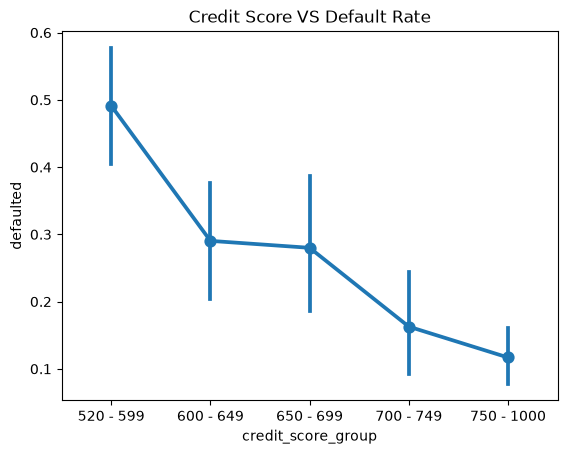

In [18]:
credit_score_order = ['520 - 599', '600 - 649', '650 - 699', '700 - 749', '750 - 1000']
sns.pointplot(data = df, x = 'credit_score_group', y = 'defaulted', order = credit_score_order)
plt.title('Credit Score VS Default Rate')
plt.show()

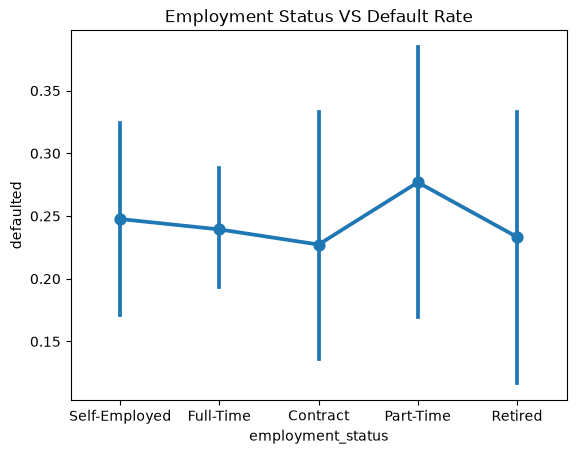

In [19]:
sns.pointplot(data = df, x = 'employment_status', y = 'defaulted')
plt.title('Employment Status VS Default Rate')
plt.show()

In [20]:
pd.DataFrame(df.groupby('employment_status')['defaulted'].mean()).sort_values(by = 'defaulted', ascending = False).reset_index()

,employment_status,defaulted
0,Part-Time,0.276923
1,Self-Employed,0.247619
2,Full-Time,0.239344
3,Retired,0.233333
4,Contract,0.227273


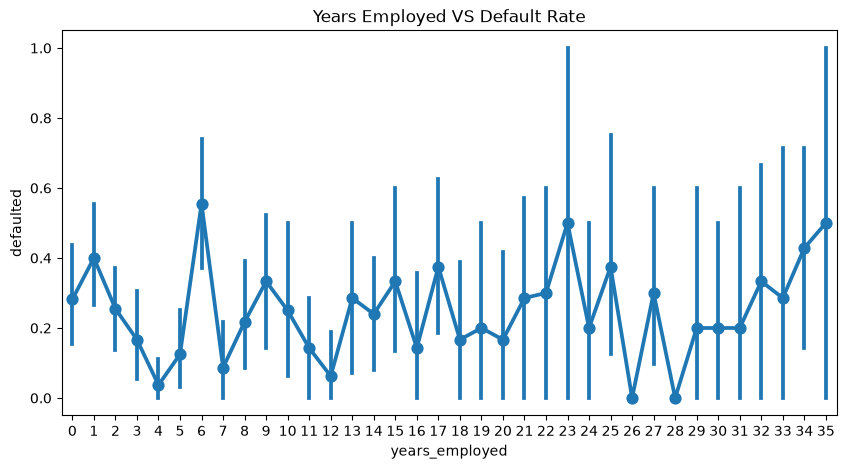

In [21]:
plt.figure(figsize = (10,5))
sns.pointplot(data = df, x = 'years_employed', y = 'defaulted')
plt.title('Years Employed VS Default Rate')
plt.show()

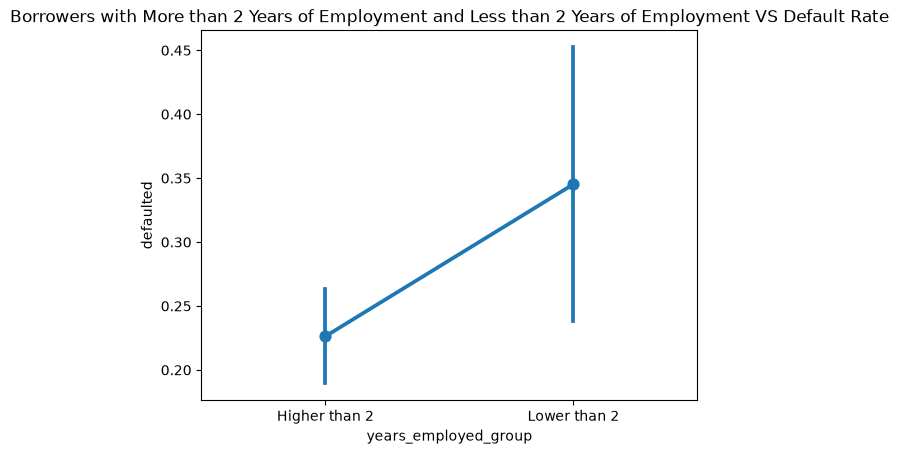

In [22]:
df['years_employed_group'] = np.where(df['years_employed'] < 2, 'Lower than 2', 'Higher than 2')
sns.pointplot(data = df, x = 'years_employed_group', y = 'defaulted')
plt.title('Borrowers with More than 2 Years of Employment and Less than 2 Years of Employment VS Default Rate')
plt.show()

In [23]:
pd.DataFrame(df.groupby('years_employed_group')['defaulted'].mean()).reset_index()

,years_employed_group,defaulted
0,Higher than 2,0.226306
1,Lower than 2,0.345238


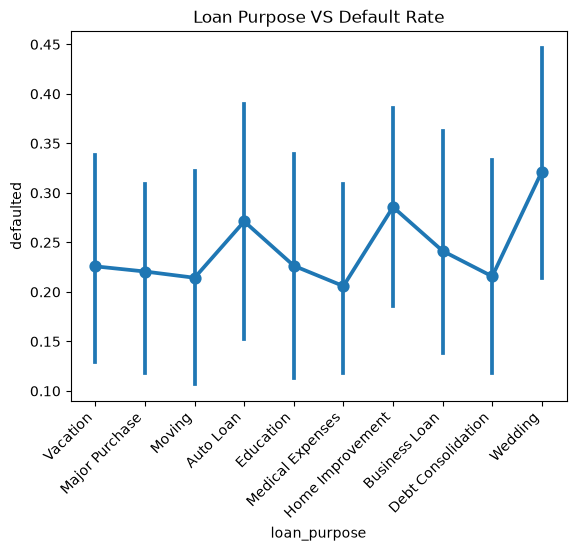

In [24]:
sns.pointplot(data = df, x = 'loan_purpose', y = 'defaulted')
plt.xticks(rotation=45, ha='right')
plt.title('Loan Purpose VS Default Rate')
plt.show()

In [25]:
pd.DataFrame(df.groupby('loan_purpose')['defaulted'].mean()).sort_values(by = 'defaulted', ascending = False).reset_index()

,loan_purpose,defaulted
0,Wedding,0.321429
1,Home Improvement,0.285714
2,Auto Loan,0.271186
3,Business Loan,0.241379
4,Education,0.226415
5,Vacation,0.225806
6,Major Purchase,0.220588
7,Debt Consolidation,0.215686
8,Moving,0.214286
9,Medical Expenses,0.205882


In [26]:
df['dti_group'] = pd.qcut(df['dti_ratio'], q = 5, precision = 1)

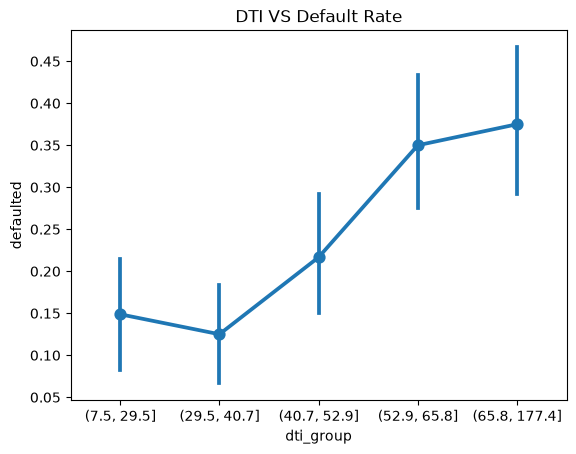

In [27]:
sns.pointplot(data = df, x = 'dti_group', y = 'defaulted')
plt.title('DTI VS Default Rate')
plt.show()

In [28]:
thresholds = [40, 45, 50, 55, 60]

data = []
for t in thresholds:
    avg = df[df['dti_ratio'] < t]['defaulted'].mean()
    data.append({'Threshold' : t , 'Average_Default_Rate_Below_Threshold' : avg})
df_data = pd.DataFrame(data)
data1 = []
for t in thresholds:
    avg = df[df['dti_ratio'] > t]['defaulted'].mean()
    data1.append({'Threshold' : t , 'Average_Default_Rate_Above_Threshold' : avg})
df_data1 = pd.DataFrame(data1)
default_rate_thresholds = pd.merge(df_data, df_data1)
default_rate_thresholds['Gap'] = default_rate_thresholds['Average_Default_Rate_Above_Threshold'] - default_rate_thresholds['Average_Default_Rate_Below_Threshold']
default_rate_thresholds

,Threshold,Average_Default_Rate_Below_Threshold,Average_Default_Rate_Above_Threshold,Gap
0,40,0.128755,0.315934,0.187179
1,45,0.151292,0.318182,0.166890
2,50,0.160606,0.344444,0.183838
3,55,0.170604,0.369863,0.199259
4,60,0.195804,0.356725,0.160921


In [29]:
df[df['dti_ratio'] > 50]['defaulted'].count()

np.int64(270)

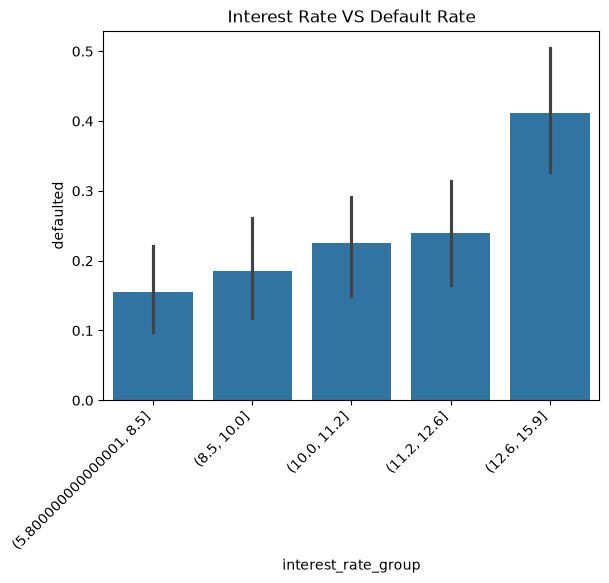

In [30]:
df['interest_rate_group'] = pd.qcut(df['interest_rate'], q = 5, precision = 1)
sns.barplot(data = df, x = 'interest_rate_group', y = 'defaulted')
plt.xticks(rotation=45, ha='right')
plt.title('Interest Rate VS Default Rate')
plt.show()

In [31]:
pd.DataFrame(df.groupby('defaulted')['loan_amount'].mean()).reset_index()

,defaulted,loan_amount
0,0,22012.747253
1,1,22570.547945


In [32]:
df.corr(method = 'pearson', numeric_only = True)['defaulted'].sort_values(ascending = False)

defaulted                1.000000
days_delinquent          0.881093
interest_rate            0.198930
dti_ratio                0.192454
existing_monthly_debt    0.083325
monthly_payment          0.061867
dependents               0.026293
loan_amount              0.018116
age                     -0.006085
years_employed          -0.007199
term_months             -0.034632
annual_income           -0.081546
credit_score            -0.286394
Name: defaulted, dtype: float64